# Red neuronal simple que aprende la operancion and

## Funcion sigmoide (similar a la distrb de Fermi)

La sigmoide transforma cualquier número en un valor entre 0 y 1.
Así podemos interpretar la salida como una predicción parecida a una probabilidad.

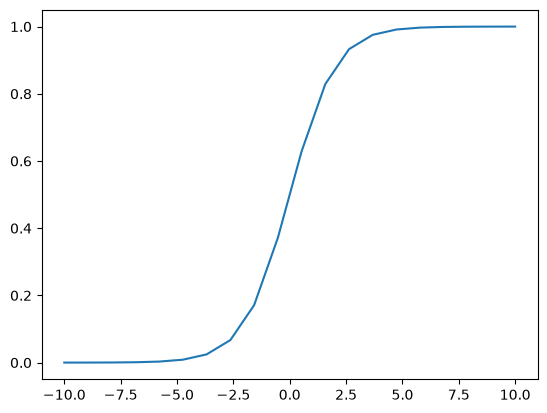

In [12]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoide(x):
    return 1 / (1 + np.exp(-x))


x = np.linspace(-10,10,20)
plt.plot(x,sigmoide(x))
plt.show()

## Ejemplos: entrada y resultado AND esperado

Cada elemento contiene:

- Una lista con las dos entradas.
- El resultado correcto que la red debe aprender.

Son los casos de la operación lógica AND: el resultado solo es 1 cuando ambas entradas son 1.

In [13]:
datos = [
    ([0, 0], 0),
    ([0, 1], 0),
    ([1, 0], 0),
    ([1, 1], 1),
]

## Pesos y sesgo iniciales

- Pesos (pesos): indican cuánto influye cada entrada en el resultado.
- Sesgo (sesgo): permite ajustar el resultado aunque las entradas sean cero.
- Tasa de aprendizaje: controla el tamaño de los cambios que la red hace al aprender. Una tasa muy grande 
  puede hacer que aprenda de forma inestable; una muy pequeña, que tarde mucho

In [14]:
pesos = [0.0, 0.0]
sesgo = 0.0
tasa_aprendizaje = 0.5

## El entrenamiento

- La red recorre todos los ejemplos 10 000 veces. Cada vuelta completa por los datos es una iteración de entrenamiento.

- Primero multiplica cada entrada por su peso, suma los resultados y añade el sesgo. Luego pasa esa suma por la sigmoide para obtener la predicción. $$ \text{suma} = \text{sesgo} + \sum_{i=0}^{n} \text{entrada}_i \cdot \text{peso}_i $$

- Error: la diferencia entre la respuesta correcta y la predicción.
- Ajuste: calcula cuánto hay que corregir, teniendo en cuenta la sigmoide.

Actualiza los pesos y el sesgo para que la próxima predicción sea más cercana a la respuesta correcta.

In [15]:
for _ in range(10_000):
    for entradas, esperado in datos:
        suma = sum(x * w for x, w in zip(entradas, pesos)) + sesgo
        prediccion = sigmoide(suma)

        error = esperado - prediccion
        ajuste = error * prediccion * (1 - prediccion)

        for i in range(len(pesos)):
            pesos[i] += tasa_aprendizaje * ajuste * entradas[i]
        sesgo += tasa_aprendizaje * ajuste

## La comprobacion final

Vuelve a calcular la salida para cada ejemplo y la muestra con tres decimales. Los resultados deberían acercarse a 0 para los tres primeros ejemplos y a 1 para [1, 1].

In [16]:
for entradas, esperado in datos:
    suma = sum(x * w for x, w in zip(entradas, pesos)) + sesgo
    print(f"{entradas} -> {sigmoide(suma):.3f} (esperado: {esperado})")

[0, 0] -> 0.000 (esperado: 0)
[0, 1] -> 0.023 (esperado: 0)
[1, 0] -> 0.023 (esperado: 0)
[1, 1] -> 0.972 (esperado: 1)


# Código entero de la red mostrando cada cambio visualmente

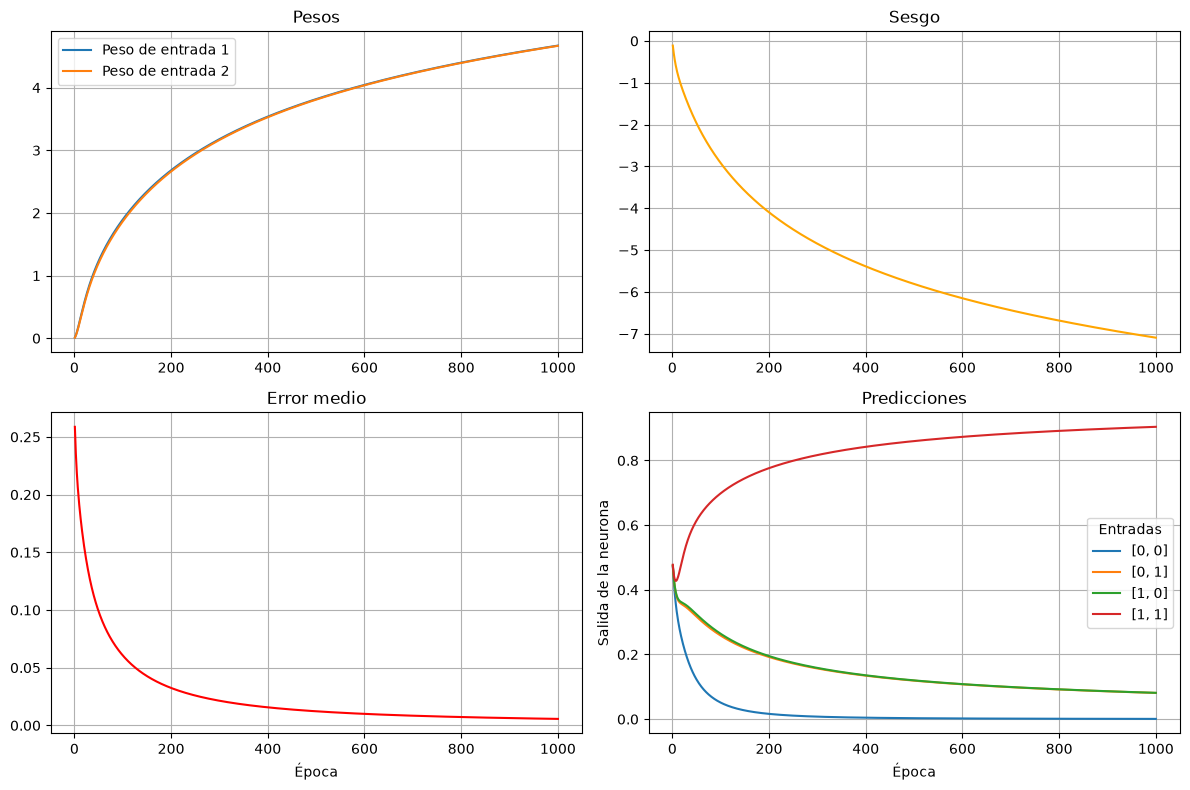

Pesos finales: [4.670941513871118, 4.6671640060319275]
Sesgo final: -7.0938552532272805


In [17]:
import math
import matplotlib.pyplot as plt

def sigmoide(x):
    return 1 / (1 + math.exp(-x))

datos = [
    ([0, 0], 0),
    ([0, 1], 0),
    ([1, 0], 0),
    ([1, 1], 1),
]

pesos = [0.0, 0.0]
sesgo = 0.0
tasa_aprendizaje = 0.5
epocas = 1000

# Guardamos los valores para poder graficarlos después
historial = {
    "peso 1": [],
    "peso 2": [],
    "sesgo": [],
    "error medio": [],
    "predicciones": [],
}

for epoca in range(epocas):
    error_total = 0

    for entradas, esperado in datos:
        # 1. La neurona calcula una predicción
        suma_ponderada = 0
        for entrada, peso in zip(entradas, pesos):
            suma_ponderada += entrada * peso

        prediccion = sigmoide(suma_ponderada + sesgo)

        # 2. Compara la predicción con la respuesta correcta
        error = esperado - prediccion
        error_total += error ** 2

        # 3. Calcula cuánto ajustar los parámetros
        ajuste = error * prediccion * (1 - prediccion)

        # 4. Actualiza los pesos y el sesgo
        for i in range(len(pesos)):
            pesos[i] += tasa_aprendizaje * ajuste * entradas[i]

        sesgo += tasa_aprendizaje * ajuste

    # Al terminar cada época, guardamos el estado de la neurona
    historial["peso 1"].append(pesos[0])
    historial["peso 2"].append(pesos[1])
    historial["sesgo"].append(sesgo)
    historial["error medio"].append(error_total / len(datos))

    # Predicciones para [0,0], [0,1], [1,0], [1,1]
    predicciones_epoca = []
    for entradas, _ in datos:
        suma_ponderada = 0
        for entrada, peso in zip(entradas, pesos):
            suma_ponderada += entrada * peso
        predicciones_epoca.append(sigmoide(suma_ponderada + sesgo))

    historial["predicciones"].append(predicciones_epoca)

# Dibujamos cómo cambian las variables durante el entrenamiento
fig, graficos = plt.subplots(2, 2, figsize=(12, 8))
eje_epocas = range(1, epocas + 1)

graficos[0, 0].plot(eje_epocas, historial["peso 1"], label="Peso de entrada 1")
graficos[0, 0].plot(eje_epocas, historial["peso 2"], label="Peso de entrada 2")
graficos[0, 0].set_title("Pesos")
graficos[0, 0].legend()
graficos[0, 0].grid(True)

graficos[0, 1].plot(eje_epocas, historial["sesgo"], color="orange")
graficos[0, 1].set_title("Sesgo")
graficos[0, 1].grid(True)

graficos[1, 0].plot(eje_epocas, historial["error medio"], color="red")
graficos[1, 0].set_title("Error medio")
graficos[1, 0].set_xlabel("Época")
graficos[1, 0].grid(True)

for i, etiqueta in enumerate(["[0, 0]", "[0, 1]", "[1, 0]", "[1, 1]"]):
    valores = [fila[i] for fila in historial["predicciones"]]
    graficos[1, 1].plot(eje_epocas, valores, label=etiqueta)

graficos[1, 1].set_title("Predicciones")
graficos[1, 1].set_xlabel("Época")
graficos[1, 1].set_ylabel("Salida de la neurona")
graficos[1, 1].legend(title="Entradas")
graficos[1, 1].grid(True)

plt.tight_layout()
plt.show()

print("Pesos finales:", pesos)
print("Sesgo final:", sesgo)

## ¿Por qué se actualizan así los pesos y el sesgo?

La neurona calcula primero una suma ponderada de las entradas:

$$
z = \sum_{i=1}^{n} x_i w_i + b
$$

donde $x_i$ son las entradas, $w_i$ sus pesos y $b$ el sesgo. Después aplica la función sigmoide:

$$
\hat{y} = \sigma(z) = \frac{1}{1 + e^{-z}}
$$

Para medir qué tan lejos está la predicción $\hat{y}$ de la respuesta correcta $y$, usamos el error cuadrático:

$$
L = \frac{1}{2}(y - \hat{y})^2
$$

El factor $\frac{1}{2}$ simplifica las derivadas. La derivada de la sigmoide es:

$$
\sigma'(z) = \sigma(z)(1 - \sigma(z))
$$

Como $\hat{y} = \sigma(z)$, también podemos escribir:

$$
\frac{\partial \hat{y}}{\partial z}
= \hat{y}(1 - \hat{y})
$$

La influencia del peso $w_i$ sobre la suma $z$ depende de la entrada $x_i$:

$$
\frac{\partial z}{\partial w_i} = x_i
$$

Y la influencia del sesgo es:

$$
\frac{\partial z}{\partial b} = 1
$$

Aplicando la regla de la cadena, obtenemos las derivadas del error respecto a cada peso:

$$
\frac{\partial L}{\partial w_i}
= (\hat{y} - y)\hat{y}(1 - \hat{y})x_i
$$

Y respecto al sesgo:

$$
\frac{\partial L}{\partial b}
= (\hat{y} - y)\hat{y}(1 - \hat{y})
$$

El descenso del gradiente resta una fracción de estas derivadas:

$$
w_i \leftarrow w_i - \eta \frac{\partial L}{\partial w_i}
$$

$$
b \leftarrow b - \eta \frac{\partial L}{\partial b}
$$

donde $\eta$ es la tasa de aprendizaje: controla el tamaño de cada paso.

En el código se define el error con el signo opuesto:

$$
\text{error} = y - \hat{y}
$$

Por eso se suma el ajuste en lugar de restar el gradiente:

$$
\text{ajuste}
= (y - \hat{y})\hat{y}(1 - \hat{y})
$$

$$
w_i \leftarrow w_i + \eta \cdot \text{ajuste} \cdot x_i
$$

$$
b \leftarrow b + \eta \cdot \text{ajuste}
$$